# COMP3122 — Assignment 1

**Applied Data Science · 12% of the course · 100 marks · due end of Week 6**

## The situation

In this assignment you act as a data-science consultant. An Associate Dean has
sent you the memo below. She must make a decision, and she is not certain that
the figure she has been given is reliable. She has attached the college's own
data, with one row per course section, and she needs an answer that is
supported by analysis.

This notebook is your answer. It has nine stages:

- Stages 1–6: the analysis
- Stage 7: the chart for the Dean
- Stage 8: your conclusions and recommendation
- Stage 9: your AI Usage Declaration

Read the memo, then read the whole notebook once before you begin.

---

> **MEMORANDUM**
>
> **To:** Data Science consultant
>
> **From:** Associate Dean, Academic Planning
>
> **Re:** Proposed expansion of online delivery
>
> Enrolment Services wants to convert **30 more sections to online delivery**
> next year. Our own numbers say online sections score **about two marks lower**
> than in-person ones, and I have been asked to sign off on the expansion by the
> end of the month.
>
> **Tell me whether that two-mark gap is a reason to say no to converting
> those 30 sections to online delivery.**
>
> Attached is the section-level export — every section we have run over four
> terms, with its program, campus, delivery mode, capacity, enrolment,
> withdrawals and mean grade.
>
> I need a one-page answer and the working behind it. If the gap is real and it
> is caused by moving online, say so and I will stop this. If it is not, I need
> to know what is actually going on, and how sure you are.

---

## What a complete answer contains

1. **The size of the gap**, measured from the data.
2. **Alternative explanations, tested with evidence.** Any other factor that
   differs between online and in-person sections could produce the gap. Show
   which factors differ and which do not.
3. **The gap measured again** with the alternative explanation held constant.
4. **A recommendation**, with your level of confidence and the evidence that
   would change it.

## How this is marked

| | Marks | Marked by |
|---|---|---|
| Stages 1–6 — the analysis: the values you store in `results` | **54** | Automatically |
| Stage 7 — the chart for the Dean | **11** | Automatically, from the Axes object |
| Stage 8 — conclusions and recommendation | **25** | Automatically |
| Stage 9 — the AI Usage Declaration, complete and signed | **10** | Automatically |
| | **100** | |

**Your answers are marked, not your method.** Each stage lists the values to
report and the precision required. The instructions do not specify which
functions to use. Two students who report the same correct values by different
methods receive the same marks.

**You may run `Validate` as often as you wish** before you submit. It runs the
same tests that are used to mark your submission; there are no hidden tests. If
Validate reports no errors, your submission will pass every test.

**Stage 8 carries the most weight.** It asks for conclusions: which finding is
reliable and what you recommend. Each conclusion follows from the values you
calculated in Stages 1–6, and each has one correct answer. Correct values with
an incorrect conclusion will lose marks.

## Rules

- Complete the stages in order. Later stages use results from earlier ones.
- **Do not reassign `sections`.** Store any filtered data under a new name.
- In Stage 8, use the exact strings shown. Any other text will fail the test.
- AI use is permitted and must be **declared in Stage 9 of this notebook**. Nothing is submitted on D2L.
- Late work loses 20% per day to a maximum of five days.


## Setup — run this cell first

This cell loads the data into `sections` and creates an empty dictionary,
`results`, where you store the value each stage asks for. Do not change this cell.

In [104]:
# Run this first. It loads the export and creates the dict you report into.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



sections = pd.read_csv("data/sections.csv")

# Every autograded value goes in here, under the key the stage names.
results = {}

print("loaded", sections.shape[0], "sections x", sections.shape[1], "columns")
sections.head()

loaded 720 sections x 11 columns


,section_id,term,program,campus,delivery,capacity,enrolled,withdrawn,contact_hours,mean_grade,is_capstone
0,SEC-0001,2024F,Software Engineering,Casa Loma,in-person,36,26,0,42,80.5,No
1,SEC-0002,2024F,Software Engineering,Casa Loma,in-person,24,18,1,42,79.3,No
2,SEC-0003,2024F,Software Engineering,Casa Loma,in-person,30,18,1,70,80.4,No
3,SEC-0004,2024F,Software Engineering,Casa Loma,in-person,42,31,0,70,75.9,No
4,SEC-0005,2024F,Software Engineering,Casa Loma,in-person,30,18,2,42,72.4,No


### Stage 1 — Describe the data

Before you evaluate the Dean's figure, describe the data you have been given.

**Store the following values in `results`:**

| key | description |
|---|---|
| `n_sections` | how many sections the export covers |
| `n_terms` | how many distinct terms |
| `overall_mean_grade` | mean `mean_grade` across every section, to 2 decimals |
| `online_share` | the share of sections delivered online, to 3 decimals |

You may use any method to calculate these values.

In [105]:
results["n_sections"] = sections["section_id"].size
results["n_terms"] =    len(sections.groupby("term"))
results["overall_mean_grade"] = np.round(np.mean(sections["mean_grade"]),2)
results["online_share"] = np.round(((sections[sections["delivery"]== "online"]).shape[0] / sections.shape[0]) ,3)

print(sections["delivery"].value_counts())
print(sections.shape)


delivery
in-person    240
online       240
hybrid       240
Name: count, dtype: int64
(720, 11)


In [106]:
assert "n_sections" in results, "results['n_sections'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("n_sections", results["n_sections"]) in {'8af38fc8556671de'}, \
    "results['n_sections'] is not correct yet"
print("ok")

ok


In [107]:
assert "n_terms" in results, "results['n_terms'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("n_terms", results["n_terms"]) in {'c5987e14ccd5c918'}, \
    "results['n_terms'] is not correct yet"
print("ok")

ok


In [108]:
assert "overall_mean_grade" in results, "results['overall_mean_grade'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("overall_mean_grade", results["overall_mean_grade"], 2) in {'6d76b5699cf106f3', 'f51a985f29df274d', '1a96c3eaf9e3046f', '5a7648a189859227', '612a807dda00d86a', 'd6cb435829ab2a82', '0c252a73b5b5e9a8', '33df67df3093daa4', 'd0e9a4d62102a22b'}, \
    "results['overall_mean_grade'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [109]:
assert "online_share" in results, "results['online_share'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("online_share", results["online_share"], 3) in {'67cdf103e4f7f210', '379b2eada703b867', '9e790ef163c51071'}, \
    "results['online_share'] is not correct yet (rounded to 3 decimals)"
print("ok")

ok


### Stage 2 — Measure the reported gap

> *"Our own numbers say online sections score about two marks lower."*

Verify this figure by calculating it from the data. Do not accept it or reject
it without checking.

**Store the following values in `results`:**

| key | description |
|---|---|
| `mean_grade_online` | mean `mean_grade` for online sections, 2 decimals |
| `mean_grade_inperson` | the same for in-person sections |
| `headline_gap` | online minus in-person, 2 decimals — negative if online is lower |
| `claim_supported` | `True` or `False`: is the Dean's "about two marks lower" a fair description of what you found? |

In [110]:
results["mean_grade_online"] = np.round(sections[sections["delivery"] == "online"]["mean_grade"].mean(), 2)
print(results["mean_grade_online"])
results["mean_grade_inperson"] = np.round(sections[sections["delivery"] == "in-person"]["mean_grade"].mean(), 2)
print(results["mean_grade_inperson"])
results["headline_gap"] = np.subtract(results["mean_grade_online"], results["mean_grade_inperson"])
print(results["headline_gap"])
results["claim_supported"] = True

72.32
74.24
-1.9200000000000017


In [111]:
assert "mean_grade_online" in results, "results['mean_grade_online'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("mean_grade_online", results["mean_grade_online"], 2) in {'3a427a392bd98224', '3fe906fbf7670ee1', 'dd3186a668d305d4', '963b179486bcecfe', 'fa487255780dbf1d', '90d5171a5ab844f8', 'd2103d8cb1993c11', '76ce6f38f370cc7e', '07a89ce32fda29ec'}, \
    "results['mean_grade_online'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [112]:
assert "mean_grade_inperson" in results, "results['mean_grade_inperson'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("mean_grade_inperson", results["mean_grade_inperson"], 2) in {'611fc266b4db4599', '8485328f9238f8d3', 'e4844aa98054d2e0', '229b631b4e9e1967', '748f7ff444aa3283', '73a789f5fc182dec', 'f63d55375d5032b9', '12564a56998a1866', '3e464cc8aec4469d'}, \
    "results['mean_grade_inperson'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [113]:
assert "headline_gap" in results, "results['headline_gap'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("headline_gap", results["headline_gap"], 2) in {'c92a7e9b2ddcd3b4', 'fe3a65ca5389a7ff', '361b39c4f750cb6d', 'f53beaf566081cb8', 'af97641a01fc430e', '9cbf2699e35889e7', 'e8c5c9c4ae099e4a', 'd47591a6c7117c49', '5f5c12b215b5784c'}, \
    "results['headline_gap'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [114]:
assert "claim_supported" in results, "results['claim_supported'] is not set"
assert isinstance(results["claim_supported"], (bool, np.bool_)), "results['claim_supported'] must be True or False"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("claim_supported", results["claim_supported"]) in {'66ea98e084e19432'}, \
    "results['claim_supported'] is not correct yet"
print("ok")

ok


### Stage 3 — Test the alternative explanations

The gap exists, but that does not prove that delivery mode *causes* it. Any
other factor that differs between online and in-person sections is an
alternative explanation. The Dean's team has suggested four:

> *"Maybe online is concentrated in the weaker programs. Or at one campus. Or in
> a particular term. Or maybe those sections are just bigger rooms."*

**Support each conclusion with evidence from the data.** A statement that the
program mix "should not matter" receives no credit. A count showing that the
program mix is identical in each delivery mode is evidence.

**Store the following values in `results`:**

| key | description |
|---|---|
| `balanced_categoricals` | list of column names, from `program`, `campus`, `term`, `is_capstone`, that have **exactly** the same number of sections in every delivery mode |
| `mean_capacity_gap` | mean `capacity` for online minus in-person, 2 decimals |
| `mean_contact_gap` | the same for `contact_hours` |
| `ruled_out` | list of every column you have now eliminated as an explanation for the grade gap |

*A column is ruled out when it does not differ between the delivery modes. A
factor that is the same in both groups cannot produce a difference between them.*

In [115]:
rows = ["program", "campus", "term", "is_capstone"]

results["balanced_categoricals"] = [
    row for row in rows
    if (sections.groupby([row, "delivery"]).size().unstack(fill_value=0).nunique(axis=1) == 1).all()
]
results["mean_capacity_gap"] = np.round(sections[sections["delivery"] == "online"]["capacity"].mean() - sections[sections["delivery"] == "in-person"]["capacity"].mean(),2)

results["mean_contact_gap"] = np.round(sections[sections["delivery"] == "online"]["contact_hours"].mean() - sections[sections["delivery"] == "in-person"]["contact_hours"].mean(),2)

results["ruled_out"] = ["capacity", "contact_hours","program", "campus", "term"]

In [116]:
assert "balanced_categoricals" in results, "results['balanced_categoricals'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("balanced_categoricals", results["balanced_categoricals"]) in {'cfa1ca9262122cc2'}, \
    "results['balanced_categoricals'] is not correct yet — check which items belong in the list"
print("ok")

ok


In [117]:
assert "mean_capacity_gap" in results, "results['mean_capacity_gap'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("mean_capacity_gap", results["mean_capacity_gap"], 2) in {'8762190d638ece9f', '34dffaa0c717f360', '712d60303fb4d118', '210ac00a3e4c8f9a', 'b3f5b6febad613ba', '38538bef195fae58', '9bc04c5373ca8d5e', '52611ee54fa6e897', 'aa9546ef28a5702f'}, \
    "results['mean_capacity_gap'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [118]:
assert "mean_contact_gap" in results, "results['mean_contact_gap'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("mean_contact_gap", results["mean_contact_gap"], 2) in {'ddab23ffbf2850f5', 'f64d44cbda9bbfe4', '07cabf30ab4210c7', '08ba371c6c672bb0', '8fcc6c02ae98e5eb', 'b22dfe1a58809465', '0a4a598bb3e2212a', '27018e3f216605b6', '59be1a2f03d6caa1'}, \
    "results['mean_contact_gap'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [119]:
assert "ruled_out" in results, "results['ruled_out'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("ruled_out", results["ruled_out"]) in {'8b2798a5a32be73e'}, \
    "results['ruled_out'] is not correct yet — check which items belong in the list"
print("ok")

ok


### Stage 4 — Identify the variable that differs

Stage 3 showed that the rooms are the same size. Examine how many students are
actually enrolled in them, and whether this is related to grades.

**Store the following values in `results`:**

| key | description |
|---|---|
| `fill_rate_online` | mean fill rate (`enrolled / capacity`) for online sections, 3 decimals |
| `fill_rate_inperson` | the same for in-person sections |
| `confounder` | the name of the one column that both differs sharply between the modes **and** moves with `mean_grade`. Report it as a string, exactly as you would name the column. |
| `grade_when_full` | mean `mean_grade` of sections at **90% full or more**, 2 decimals |
| `grade_when_empty` | mean `mean_grade` of sections **under 70% full**, 2 decimals |

The last two values are the evidence for your answer to `confounder`. If they
are nearly equal, you have chosen the wrong column.

In [120]:

results["fill_rate_online"] = np.round(np.divide(sections[sections["delivery"] == "online"]["enrolled"].mean(), sections[sections["delivery"] == "online"]["capacity"].mean()),3)
results["fill_rate_inperson"] = np.round(np.divide(sections[sections["delivery"] == "in-person"]["enrolled"].mean(), sections[sections["delivery"] == "in-person"]["capacity"].mean()),3)
results["confounder"] = "fill_rate"
results["grade_when_full"] = np.round(sections[np.divide(sections["enrolled"], sections["capacity"]) * 100 >= 90]["mean_grade"].mean(),2)
results["grade_when_empty"] = np.round(sections[np.divide(sections["enrolled"], sections["capacity"]) * 100 < 70]["mean_grade"].mean(),2)

# print(results["grade_when_full"])
# print(results["grade_when_empty"])

In [121]:
assert "fill_rate_online" in results, "results['fill_rate_online'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("fill_rate_online", results["fill_rate_online"], 3) in {'1af6877fb2370f03', '07ab647b61218433', '9279c6b1603af7c2'}, \
    "results['fill_rate_online'] is not correct yet (rounded to 3 decimals)"
print("ok")

ok


In [122]:
assert "fill_rate_inperson" in results, "results['fill_rate_inperson'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("fill_rate_inperson", results["fill_rate_inperson"], 3) in {'df9e2c3c7c5d5d08', '07d921557422a769', '38aae4d91049b05b'}, \
    "results['fill_rate_inperson'] is not correct yet (rounded to 3 decimals)"
print("ok")

ok


In [123]:
assert "confounder" in results, "results['confounder'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("confounder", results["confounder"]) in {'441bdcf915d40594'}, \
    "results['confounder'] is not correct yet"
print("ok")

ok


In [124]:
assert "grade_when_full" in results, "results['grade_when_full'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("grade_when_full", results["grade_when_full"], 2) in {'3129b120ffd9ac12', '022f28580db8c978', '112ae2cc0070e51b', 'e478eaf5a7cdb14e', 'd70256c337fbccba', 'a0e4e8277fe8379b', '116bd11ed9754ff5', 'b82e3955349f8a35', '14bbf8930f5a4983'}, \
    "results['grade_when_full'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [125]:
assert "grade_when_empty" in results, "results['grade_when_empty'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("grade_when_empty", results["grade_when_empty"], 2) in {'889b9683e4de588f', '0c2a0e0a9d0284cf', '5748fb54b31764a8', '2ecdb8cde29a110d', '0f1faa8c417148a9', '19e8fc5743c67da5', '6889e4c95e96ca1b', '0a78346fd27a083e', '1bd85bc397fd3d67'}, \
    "results['grade_when_empty'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


### Stage 5 — Compare sections with similar fill rates

> *"If it's really about how full the rooms are, then show me the comparison with
> that held still. Use sections that ran under 75% full — I want like against
> like."*

Use the Dean's threshold of 75% exactly, so that your result can be compared
with other analyses.

**Store the following values in `results`:**

| key | description |
|---|---|
| `adjusted_gap` | online minus in-person mean grade, **among sections under 75% full**, 2 decimals |
| `n_online_adjusted` | how many online sections that average rests on |
| `gap_direction_changed` | `True` or `False`: does `adjusted_gap` have the opposite sign to `headline_gap`? |

**Before you draw a conclusion from `adjusted_gap`, check how large `n_online_adjusted` is.**

In [126]:
results["adjusted_gap"] = np.round(np.subtract(sections[(sections["delivery"] == "online") & ((sections["enrolled"] / sections["capacity"]) * 100 < 75)]["mean_grade"].mean(),sections[(sections["delivery"] == "in-person") & ((sections["enrolled"] / sections["capacity"]) * 100 < 75)]["mean_grade"].mean()),2)
results["n_online_adjusted"] = int((sections[sections["enrolled"] / sections["capacity"] < 0.75]["delivery"] == "online").sum())

results["gap_direction_changed"] = True

In [127]:
assert "adjusted_gap" in results, "results['adjusted_gap'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("adjusted_gap", results["adjusted_gap"], 2) in {'a70155ce5ae600d5', '3b4e72ec29a7168f', '5e166972302edff2', '401d1054a7d64fcc', 'fdf6dd6312acec70', '3b7d6fd7d3d269dc', '8fcf07870d4d4307', '1a9efe7214a2e5ad', 'fabbcc795c63c431'}, \
    "results['adjusted_gap'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [128]:
assert "n_online_adjusted" in results, "results['n_online_adjusted'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("n_online_adjusted", results["n_online_adjusted"]) in {'bc8ee7a806a8cb70'}, \
    "results['n_online_adjusted'] is not correct yet"
print("ok")

ok


In [129]:
assert "gap_direction_changed" in results, "results['gap_direction_changed'] is not set"
assert isinstance(results["gap_direction_changed"], (bool, np.bool_)), "results['gap_direction_changed'] must be True or False"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("gap_direction_changed", results["gap_direction_changed"]) in {'4decd6bf2fb34fad'}, \
    "results['gap_direction_changed'] is not correct yet"
print("ok")

ok


### Stage 6 — Test the finding at a second threshold

A result that appears at only one threshold may not be reliable. Change the
threshold from 75% to **80%** and repeat the comparison.

**Store the following values in `results`:**

| key | description |
|---|---|
| `adjusted_gap_80` | online minus in-person mean grade, among sections under 80% full |
| `n_online_adjusted_80` | how many online sections that rests on |

Compare the three gaps (`headline_gap`, `adjusted_gap` and `adjusted_gap_80`) and
the two sample sizes. **One of the two findings from Stage 5 still holds at 80%,
and one does not.** Identifying which one holds is the most important part of
your answer to the Dean.

In [130]:
results["adjusted_gap_80"] = np.round(np.subtract(sections[(sections["delivery"] == "online") & ((sections["enrolled"] / sections["capacity"]) * 100 < 80)]["mean_grade"].mean(),sections[(sections["delivery"] == "in-person") & ((sections["enrolled"] / sections["capacity"]) * 100 < 80)]["mean_grade"].mean()),2)
results["n_online_adjusted_80"] = int((sections[sections["enrolled"] / sections["capacity"] < 0.80]["delivery"] == "online").sum())

In [131]:
assert "adjusted_gap_80" in results, "results['adjusted_gap_80'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("adjusted_gap_80", results["adjusted_gap_80"], 2) in {'3c540564ec5f383a', '6ba1f51a2d9d9417', '1e663abb2d255a29', '6f2ad991c27c946e', '873c75fbabe72f50', '2000d6ecaab591fc', '61eaa628f6606884', '5c326b85c38f9b36', 'c3c9132235f974a3'}, \
    "results['adjusted_gap_80'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [132]:
assert "n_online_adjusted_80" in results, "results['n_online_adjusted_80'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("n_online_adjusted_80", results["n_online_adjusted_80"]) in {'55dcc934660ca7f1'}, \
    "results['n_online_adjusted_80'] is not correct yet"
print("ok")

ok


### Stage 7 — The chart for the Dean

The Dean will review one chart rather than a table of results.

Draw a **scatter plot** of every section: fill rate on the x-axis, mean grade on
the y-axis, **one point per section**. Draw each delivery mode as a **separate
series** so that the reader can distinguish them. The data contains three modes,
not two: include the hybrid sections, even though the memo does not mention them.

The chart requires:

- a title
- an x-axis label that names the fill rate
- a y-axis label that names the grade
- a legend whose entries match the mode names in the data: *online*, *in-person*, *hybrid*

Store the Axes object in `results["ax"]`. The tests read the Axes object (the
number of series and points, the labels and the legend), not the image.

*For reference, see Chapter 5: `fig, ax = plt.subplots()`, then `ax.scatter(...)`
once per series with `label=`, then `ax.legend()`.*

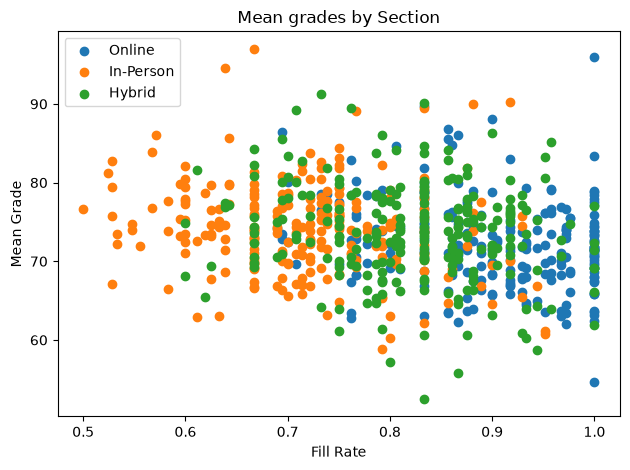

In [133]:
fig, ax = plt.subplots()

ax.scatter( np.round(np.divide(sections[sections["delivery"] == "online"]["enrolled"], sections[sections["delivery"] == "online"]["capacity"]),3), sections[sections["delivery"] == "online"]["mean_grade"],label="Online")

ax.scatter(np.round(np.divide(sections[sections["delivery"] == "in-person"]["enrolled"], sections[sections["delivery"] == "in-person"]["capacity"]),3), sections[sections["delivery"] == "in-person"]["mean_grade"],label="In-Person")

ax.scatter(np.round(np.divide(sections[sections["delivery"] == "hybrid"]["enrolled"], sections[sections["delivery"] == "hybrid"]["capacity"]), 3), sections[sections["delivery"] == "hybrid"]["mean_grade"],label="Hybrid")
ax.legend()
ax.set_xlabel("Fill Rate")
ax.set_ylabel( "Mean Grade")
ax.set_title("Mean grades by Section")
plt.tight_layout()
results["ax"] = ax


In [134]:
assert "ax" in results, "results['ax'] is not set — store the Axes you drew on"
import matplotlib.axes
assert isinstance(results["ax"], matplotlib.axes.Axes), "results['ax'] must be a Matplotlib Axes"
assert len(results["ax"].collections) == 3, \
    f"expected three scatter series (one per delivery mode), found {len(results['ax'].collections)}"
print("ok")

ok


In [135]:
assert "ax" in results, "results[ax] is not set - store the Axes you drew on"
ax = results["ax"]
n = sum(len(c.get_offsets()) for c in ax.collections)
assert n == 720, f"expected one point per section (720), found {n}"
xs = [x for c in ax.collections for x, _ in c.get_offsets()]
assert 0 <= min(xs) and max(xs) <= 1.5, "x must be the fill rate (enrolled / capacity)"
print("ok")

ok


In [136]:
assert "ax" in results, "results[ax] is not set - store the Axes you drew on"
ax = results["ax"]
assert ax.get_title().strip(), "the plot has no title"
assert "fill" in ax.get_xlabel().lower(), f"x-axis label should name the fill rate, got {ax.get_xlabel()!r}"
assert "grade" in ax.get_ylabel().lower(), f"y-axis label should name the grade, got {ax.get_ylabel()!r}"
print("ok")

ok


In [137]:
assert "ax" in results, "results[ax] is not set - store the Axes you drew on"
ax = results["ax"]
leg = ax.get_legend()
assert leg is not None, "no legend — the reader cannot tell online from in-person"
labels = sorted(t.get_text().lower() for t in leg.get_texts())
assert labels == ["hybrid", "in-person", "online"], f"legend should read hybrid / in-person / online, got {labels}"
print("ok")

ok


### Stage 8 — Conclusions and recommendation

This stage records the conclusions of your analysis. Each entry follows from
values you have already calculated; no new calculation is needed. Where a value
is a **choice**, use the exact string shown.

**Store the following values in `results`:**

| key | description |
|---|---|
| `shrinkage_robust` | `True` or `False`: is the gap **smaller in size** than `headline_gap` at *both* thresholds (75% and 80%)? |
| `reversal_robust` | `True` or `False`: does the sign flip you saw at 75% **still hold** at 80%? |
| `gap_explained_by_delivery` | `True` or `False`: once fill rate is held still, is delivery mode itself what produces the two-mark gap? |
| `crowding_penalty` | `grade_when_empty` minus `grade_when_full`, 2 decimals — how many marks a full room costs |
| `defend_in_meeting` | which finding you would defend to the Dean — one of `"headline_gap_is_causal"`, `"gap_shrinks_with_fill_held_still"`, `"online_beats_inperson_when_not_full"` |
| `would_not_defend` | which of those three findings you would **not** defend. Consider how many sections it is based on (`n_online_adjusted`). |
| `fill_cap_for_parity` | the loosest threshold in your analysis (`0.75` or `0.80`) at which online sections score **at least as well** as in-person ones — the number a condition on the expansion would be written on |
| `missing_column` | the one thing this export does not contain that would let you test the same teacher in both modes — one of `"instructor"`, `"capacity"`, `"program"`, `"term"` |
| `recommendation` | one of `"refuse"`, `"approve"`, `"approve_with_condition"`, `"cannot_tell"` |

**On `recommendation`:** two of the four options are supported by this data and
two are not. *Refuse* accepts the Dean's figure even though your analysis shows
the gap is not caused by delivery mode. *Cannot tell* ignores a reduction in the
gap that holds at both thresholds. If you attach a condition, it
is the fill cap.

In [138]:
results["shrinkage_robust"] = True
results["reversal_robust"] = False
results["gap_explained_by_delivery"] = False
results["crowding_penalty"] = np.round(results["grade_when_empty"] - results["grade_when_full"],2)
results["defend_in_meeting"] = "gap_shrinks_with_fill_held_still"
results["would_not_defend"] = "online_beats_inperson_when_not_full"
results["fill_cap_for_parity"] = "0.75"
results["missing_column"] = "instructor"
results["recommendation"] = "approve_with_condition" 

In [139]:
assert "shrinkage_robust" in results, "results['shrinkage_robust'] is not set"
assert isinstance(results["shrinkage_robust"], (bool, np.bool_)), "results['shrinkage_robust'] must be True or False"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("shrinkage_robust", results["shrinkage_robust"]) in {'1db765a8f650a53f'}, \
    "results['shrinkage_robust'] is not correct yet"
print("ok")

ok


In [140]:
assert "reversal_robust" in results, "results['reversal_robust'] is not set"
assert isinstance(results["reversal_robust"], (bool, np.bool_)), "results['reversal_robust'] must be True or False"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("reversal_robust", results["reversal_robust"]) in {'88bda3e140c676b0'}, \
    "results['reversal_robust'] is not correct yet"
print("ok")

ok


In [141]:
assert "gap_explained_by_delivery" in results, "results['gap_explained_by_delivery'] is not set"
assert isinstance(results["gap_explained_by_delivery"], (bool, np.bool_)), "results['gap_explained_by_delivery'] must be True or False"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("gap_explained_by_delivery", results["gap_explained_by_delivery"]) in {'fc0409207a121996'}, \
    "results['gap_explained_by_delivery'] is not correct yet"
print("ok")

ok


In [142]:
assert "crowding_penalty" in results, "results['crowding_penalty'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("crowding_penalty", results["crowding_penalty"], 2) in {'4813d7a17800533a', 'a03777054f75f76c', 'cd20299ddbdddba6', '63265f97ecb8c70d', '1970f18bd60a3a65', 'c92c094deda1cb8c', '9fc5ddab2b344676', '278d3ff569f7d4e5', '408cd16b7814837d'}, \
    "results['crowding_penalty'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [143]:
assert "defend_in_meeting" in results, "results['defend_in_meeting'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("defend_in_meeting", results["defend_in_meeting"]) in {'b4a2ade436cca235'}, \
    "results['defend_in_meeting'] is not correct yet"
print("ok")

ok


In [144]:
assert "would_not_defend" in results, "results['would_not_defend'] is not set"
import hashlib
import numpy as np
import pandas as pd

def _fp(key, x, dp=None):
    results["would_not_defend"] = "cannot_tell"
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("would_not_defend", results["would_not_defend"]) in {'2ba764292c24ec61'}, \
    "results['would_not_defend'] is not correct yet"
print("ok")

ok


In [145]:
assert "fill_cap_for_parity" in results, "results['fill_cap_for_parity'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("fill_cap_for_parity", results["fill_cap_for_parity"], 2) in {'a6b89bd80bcce6d4', 'a4712240dff69bd7', 'f14e34ba10c9212e', '8db38beb889904b7', 'ca2968d92016b9be', 'fda7d18e545dddfb', '6ae856581aaa74a4', '2e9b9316cff0e45a', '575e9a524ebc6321'}, \
    "results['fill_cap_for_parity'] is not correct yet (rounded to 2 decimals)"
print("ok")

ok


In [146]:
assert "missing_column" in results, "results['missing_column'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("missing_column", results["missing_column"]) in {'48b1cfbf0080a161'}, \
    "results['missing_column'] is not correct yet"
print("ok")

ok


In [147]:
assert "recommendation" in results, "results['recommendation'] is not set"
import hashlib
import numpy as np
import pandas as pd
def _fp(key, x, dp=None):
    if isinstance(x, (bool, np.bool_)):
        s = "b:" + str(bool(x))
    elif dp is not None:
        s = "f:" + format(round(float(x), dp) + 0.0, f".{dp}f")
    elif isinstance(x, (int, np.integer)) or (isinstance(x, float) and float(x).is_integer()):
        s = "i:" + str(int(x))
    elif isinstance(x, (list, tuple, set, np.ndarray, pd.Index, pd.Series)):
        s = "l:" + "|".join(sorted(map(str, list(x))))
    else:
        s = "s:" + str(x)
    return hashlib.sha256(f"a1|{key}|{s}".encode()).hexdigest()[:16]
assert _fp("recommendation", results["recommendation"]) in {'ca8475c8f2e86735', '8033632fdabcfcaa'}, \
    "results['recommendation'] is not correct yet — use one of the exact strings listed in the brief"
print("ok")

ok


### Stage 9 — AI Usage Declaration · 10 marks

AI use is **permitted** on this assignment, with proper referencing. The
college's AI Usage Declaration is filed **here, in this notebook** — not on D2L.
Fill in the `declaration` dict in the cell below; it asks exactly what the
college form asks. The checks confirm the declaration is **complete** (every
field answered, both statements agreed to). They cannot check whether it is
true. You are responsible for its accuracy, and the academic-integrity policy applies.

**If you did not use AI:** set `used_ai` to `False`, give your name and student
number, agree to both statements, and leave the lists empty. That is a complete
declaration and earns the full 10 marks.

**If you used AI:** complete every field. `details` should say *what* AI produced and
*which stages* it touched (for example, "Copilot suggested the mask in Stage 3;
I rewrote it"). Use the exact strings shown for the list entries; `"Other: …"`
is allowed in each list with your own text after the colon.

| key | description |
|---|---|
| `name` | your full name, as registered |
| `student_id` | your 9-digit student number, as a string |
| `used_ai` | `True` or `False` |
| `tools` | any of `"ChatGPT"`, `"Copilot"`, `"DALL-E"`, `"Other: …"` — empty if `used_ai` is `False` |
| `purposes` | any of `"Idea Generation"`, `"Writing Assistance"`, `"Image Creation"`, `"Coding/Programming"`, `"Language Refinement"`, `"Other: …"` |
| `details` | what AI produced and where you used it |
| `review` | any of `"Edited AI output for accuracy"`, `"Cross-checked AI output with reliable sources"`, `"Made significant changes to AI output"`, `"Other: …"` |
| `quality_check` | how you made sure the AI-assisted work was right |
| `ethical_use` | how you kept the work your own |
| `reflection` | one or two sentences on how AI helped, or did not |
| `accurate_and_truthful` | `True` — *I declare that the information in this AI Usage Declaration is accurate and truthful, and that I have referenced all AI-generated content used.* |
| `own_work` | `True` — *I declare that the work submitted is my own, that AI was used only as a tool to assist me, and that I am responsible for its content and quality.* |

In [153]:
declaration = {
    "name": "Christian Garica Flores",
    "student_id": "101543437",
    "used_ai": True,
    "tools": ["Other: Gemini"],
    "purposes": ["Idea Generation"],
    "details": "Produced further explanations to some of the question",
    "review": ["Edited AI output for accuracy"],
    "quality_check": "Repeated back what I thought so we could align on the same vision",
    "ethical_use": "The code was mine, understanding the questions was me with the use of AI",
    "reflection": "In my opinion, some of the questions were not asked in a clear method and so using AI to eliminate some ideas for what the answer might be looking for was effective.",
    "accurate_and_truthful": True,
    "own_work": True,
}

for k, v in declaration.items():
    print(f"{k:22} {v!r}")

name                   'Christian Garica Flores'
student_id             '101543437'
used_ai                True
tools                  ['Other: Gemini']
purposes               ['Idea Generation']
details                'Produced further explanations to some of the question'
review                 ['Edited AI output for accuracy']
quality_check          'Repeated back what I thought so we could align on the same vision'
ethical_use            'The code was mine, understanding the questions was me with the use of AI'
reflection             'In my opinion, some of the questions were not asked in a clear method and so using AI to eliminate some ideas for what the answer might be looking for was effective.'
accurate_and_truthful  True
own_work               True


In [151]:
assert "declaration" in dir(), "the declaration dict is missing — run the cell above"
d = declaration
assert isinstance(d.get("name"), str) and len(d["name"].strip()) >= 3, "declaration: name is empty"
sid = str(d.get("student_id", "")).strip()
assert sid.isdigit() and len(sid) == 9, f"declaration: student_id must be your 9-digit student number, got {sid!r}"
print("ok")

ok


In [154]:
d = declaration
assert d.get("used_ai") in (True, False), "declaration: used_ai must be True or False"
TOOLS = ["ChatGPT", "Copilot", "DALL-E"]
PURPOSES = ["Idea Generation", "Writing Assistance", "Image Creation", "Coding/Programming", "Language Refinement"]
ok = lambda xs, allowed: isinstance(xs, list) and all(x in allowed or str(x).startswith("Other: ") for x in xs)
assert ok(d.get("tools"), TOOLS), f"declaration: tools must use the exact strings shown, got {d.get('tools')!r}"
assert ok(d.get("purposes"), PURPOSES), f"declaration: purposes must use the exact strings shown, got {d.get('purposes')!r}"
if d["used_ai"]:
    assert d["tools"], "declaration: used_ai is True but no tool is named"
    assert d["purposes"], "declaration: used_ai is True but no purpose is selected"
else:
    assert not d["tools"] and not d["purposes"], "declaration: used_ai is False but tools/purposes are not empty"
print("ok")

ok


In [155]:
d = declaration
assert d.get("used_ai") in (True, False), "declaration: used_ai must be True or False"
REVIEW = ["Edited AI output for accuracy", "Cross-checked AI output with reliable sources", "Made significant changes to AI output"]
assert isinstance(d.get("review"), list) and all(x in REVIEW or str(x).startswith("Other: ") for x in d["review"]), \
    f"declaration: review must use the exact strings shown, got {d.get('review')!r}"
for k in ["details", "quality_check", "ethical_use", "reflection"]:
    assert isinstance(d.get(k), str), f"declaration: {k} must be a string"
if d.get("used_ai"):
    assert len(d["details"].strip()) >= 20, "declaration: details — say what AI produced and which stages it touched"
    assert d["review"], "declaration: used_ai is True but no review action is selected"
    for k in ["quality_check", "ethical_use", "reflection"]:
        assert len(d[k].strip()) >= 10, f"declaration: {k} is empty"
print("ok")

ok


In [156]:
d = declaration
assert d.get("accurate_and_truthful") is True, "declaration: accurate_and_truthful must be True — the declaration is not signed"
assert d.get("own_work") is True, "declaration: own_work must be True — the original-work declaration is not signed"
print("ok")

ok


---

## Before you submit

1. **Kernel → Restart Kernel and Run All Cells.** Every test must print `ok` from a
   clean start. `Validate` runs exactly these tests — there are no hidden ones.
2. **Stage 9 is filled in** — name, student number, the AI questions, both
   statements. An incomplete declaration costs 10 marks and Validate tells you
   which field is missing. Nothing is filed on D2L for this assignment.
3. **Submit** through *Nbgrader → Assignment List* in Jupyter. You can submit more
   than once before the deadline; the last submission is the one marked.
4. Late work loses 20% per day to a maximum of five days.
